# Friday Night: a fuzzy evening planner

- [ ] Don’t develop non fuzzy stuff, not enough time
- [ ] Concentrate on the fuzzy part!!!
- [ ] Come up with fuzzy rules for the recommender system
- [ ] Make a small evaluation of our work - does this make sense to other people? How do we evaluate this prototype?

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

X = np.linspace(0, 10, 1001)  # hidden 0-10 scale behind every word
Y = np.linspace(0, 1, 501)    # answer scale: 0 = no, 1 = yes


def shape(a, b, c, d, x=X):
    """Trapezoid fuzzy set: rises from a to b, stays at 1 until c, falls to d."""
    up = (x >= a).astype(float) if b == a else (x - a) / (b - a)
    down = (x <= d).astype(float) if d == c else (d - x) / (d - c)
    return np.clip(np.minimum(up, down), 0, 1)


def possibility(a, b):
    """How much two fuzzy sets overlap (sup-min)."""
    return float(np.max(np.minimum(a, b)))


def centroid(m):
    return float((Y * m).sum() / m.sum()) if m.sum() else 0.5


def show_md(text):
    display(Markdown(text))

Money: we need a min max slider for money with a normal distrbution from each point with all values between at 100.

distance: we need a equality contratin set to 100 for all values less than what was said 


crirps filter for kids. then a maturity rating. a filter for kids can come along and then a event for kids.  watching fozen is for kids while a comidy movie you can birng a kids along.

for time its crips and if we can we try to make a flight scanner price date. 
if we can think of cool events on 

In [ ]:
energy 

# Words

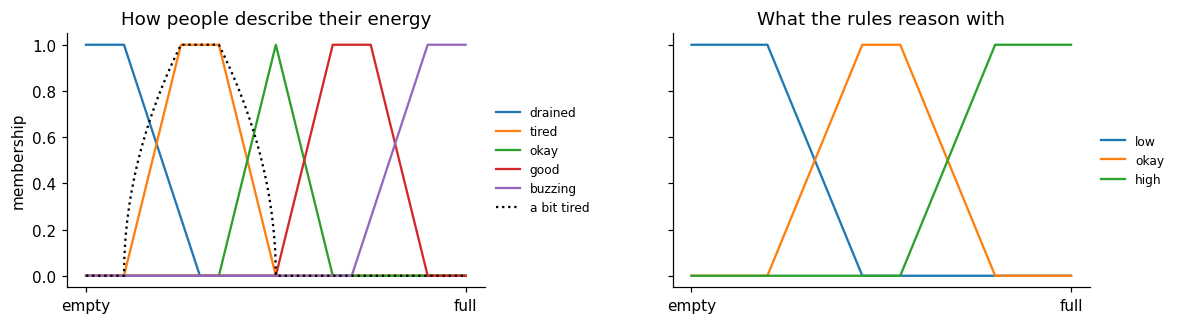

In [2]:
# Each word is a trapezoid (a, b, c, d) on the hidden 0-10 scale
WORDS = {
    # about you
    'battery':   {'drained': (0, 0, 1, 3), 'tired': (1, 2.5, 3.5, 5), 'okay': (3.5, 5, 5, 6.5),
                  'good': (5, 6.5, 7.5, 9), 'buzzing': (7, 9, 10, 10)},
    'wallet':    {'broke': (0, 0, 1, 2.5), 'tight': (1, 2.5, 3.5, 5), 'fine': (3.5, 5, 6, 7.5),
                  'treat myself': (6.5, 8.5, 10, 10)},
    # about the event
    'intensity': {'chill': (0, 0, 1, 3), 'mellow': (1, 3, 4, 5.5), 'lively': (4, 5.5, 6.5, 8),
                  'loud': (6, 7.5, 8.5, 10), 'wild': (8, 9.5, 10, 10)},
    'price':     {'free': (0, 0, 0, 1), 'cheap': (0, 1.5, 2.5, 4), 'moderate': (3, 4.5, 5.5, 7),
                  'pricey': (6, 7.5, 8.5, 10), 'splurge': (8, 9.5, 10, 10)},
    'special':   {'any week': (0, 0, 1, 3), 'nice change': (2, 4, 5, 7), 'rare': (5.5, 7, 8, 9.5),
                  'once a year': (8, 9.5, 10, 10)},
    'travel':    {'next door': (0, 0, 1, 2.5), 'short trip': (1.5, 3, 4, 5.5), 'a trek': (5, 6.5, 7.5, 9),
                  'a day out': (7.5, 9, 10, 10)},
}

HEDGES = {'very': lambda m: m ** 2, 'a bit': np.sqrt, 'somewhat': np.sqrt}


def word(var, text):
    """'a bit tired' -> fuzzy set on the 0-10 scale."""
    text = text.strip().lower()
    for hedge, f in HEDGES.items():
        if text.startswith(hedge + ' '):
            return f(word(var, text[len(hedge) + 1:]))
    return shape(*WORDS[var][text])


# The three levels the rules reason with
LEVELS = {'low': shape(0, 0, 2, 4.5), 'mid': shape(2, 4.5, 5.5, 8), 'high': shape(5.5, 8, 10, 10)}

LABEL = {  # short names of low / mid / high, per variable
    'battery': ('low', 'okay', 'high'),       'intensity': ('chill', 'lively', 'wild'),
    'wallet': ('tight', 'fine', 'treat'),     'price': ('cheap', 'costs a bit', 'pricey'),
    'special': ('ordinary', 'nice change', 'rare'), 'travel': ('close', 'short trip', 'far'),
}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3), sharey=True, gridspec_kw={'wspace': 0.45})
for w in WORDS['battery']:
    ax1.plot(X, word('battery', w), label=w)
ax1.plot(X, word('battery', 'a bit tired'), 'k:', label='a bit tired')
ax1.set_title('How people describe their energy')
for m, lab in zip(LEVELS.values(), LABEL['battery']):
    ax2.plot(X, m, label=lab)
ax2.set_title('What the rules reason with')
for ax in (ax1, ax2):
    ax.set_xticks([0, 10], ['empty', 'full'])
    ax.legend(frameon=False, fontsize=8, loc='center left', bbox_to_anchor=(1, 0.5))
ax1.set_ylabel('membership')
plt.show()

## Money range

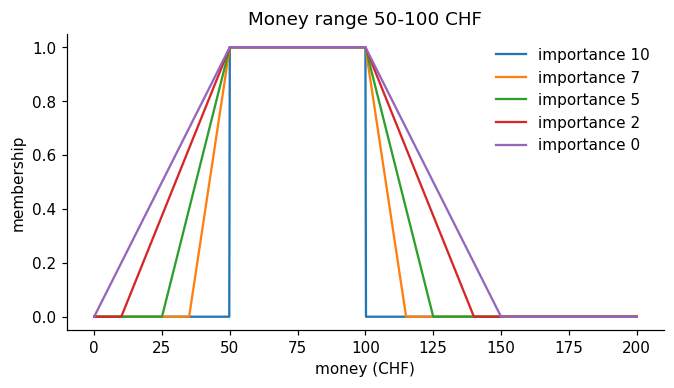

In [ ]:
MAX_CHF = 200 # CHF amount that corresponds to 10 on the hidden 0-10 scale
SOFTNESS = 1.0 # how wide the slopes get at importance 0 (1.0 = as wide as the range)


def money_membership(max_money, importance, min_money=0, x=X):
    """Fuzzy set for 'how much I want to spend', on the grid x.

    max_money   upper end of the range
    min_money   lower end of the range (default 0)
    importance  0-10: 10 = crisp rectangle, 0 = very soft slopes
    All money values must be on the same scale as x.
    """
    importance = float(np.clip(importance, 0, 10))
    softness = (10 - importance) / 10 # 0 = crisp, ..., 1 = very soft slope
    w = softness * SOFTNESS * (max_money - min_money) # width of each slope

    a = max(min_money - w, 0)
    b = min_money
    c = max_money
    d = max_money + w
    return shape(a, b, c, d, x)


def money_set(max_chf, importance, min_chf=0):
    """Money range in CHF -> fuzzy set on the notebook's 0-10 scale X."""
    s = 10 / MAX_CHF
    return money_membership(max_chf * s, importance, min_chf * s, x=X)


# Plot: same range, different importance
fig, ax = plt.subplots(figsize=(7, 3.5))
for imp in [10, 7, 5, 2, 0]:
    ax.plot(X * MAX_CHF / 10, money_set(100, imp, 50), label=f'importance {imp}')
ax.set_xlabel('money (CHF)')
ax.set_ylabel('membership')
ax.set_title('Money range 50-100 CHF')
ax.legend(frameon=False)
plt.show()

## Events


In [3]:
def event(name, intensity, price, special, travel, occasion, company):
    o = dict(zip(['unwind', 'catch up', 'celebrate', 'new', 'date'], occasion))
    c = dict(zip(['solo', 'partner', 'friends', 'big group', 'kids'], company))
    return dict(name=name, intensity=intensity, price=price, special=special, travel=travel, occasion=o, company=c)

#                                                                    unwind, catch up, celebrate, new, date   solo, partner, friends, big group, kids
EVENTS = [
    event('Board game café',       'mellow', 'cheap',    'any week',    'next door',  (.6, 1, .3, .3, .6),   (.2, .8, 1, .5, .8)),
    event('Indie cinema',          'chill',  'cheap',    'any week',    'next door',  (.9, .2, .2, .4, .7),  (1, .9, .6, .3, .5)),
    event('Jazz in a small bar',   'mellow', 'moderate', 'nice change', 'short trip', (.8, .7, .5, .5, 1),   (.7, 1, .7, .2, .1)),
    event('Thermal spa evening',   'chill',  'pricey',   'nice change', 'short trip', (1, .6, .5, .3, .8),   (.8, 1, .6, .2, .3)),
    event('Pottery workshop',      'chill',  'moderate', 'nice change', 'next door',  (.7, .6, .3, 1, .7),   (.8, .9, .8, .3, .6)),
    event('Comedy open mic',       'lively', 'cheap',    'any week',    'short trip', (.6, .5, .4, .6, .6),  (.6, .8, .9, .6, 0)),
    event('Karaoke night',         'loud',   'cheap',    'any week',    'next door',  (.3, .4, .9, .4, .3),  (.1, .4, 1, 1, .2)),
    event("Friend's house party",  'loud',   'free',     'any week',    'next door',  (.3, .8, .8, .1, .3),  (.6, .7, 1, 1, 0)),
    event('Tasting menu dinner',   'mellow', 'splurge',  'rare',        'short trip', (.5, .7, 1, .6, 1),    (.2, 1, .7, .3, .1)),
    event('Full-moon hike',        'lively', 'free',     'rare',        'a trek',     (.7, .8, .4, .9, .7),  (.3, .9, .9, .5, .4)),
    event('Lantern parade',        'lively', 'free',     'once a year', 'next door',  (.5, .4, .6, .6, .4),  (.4, .7, .7, .8, 1)),
    event('Techno open-air',       'wild',   'moderate', 'rare',        'a trek',     (.1, .2, 1, .5, .3),   (.5, .6, 1, .9, 0)),
    event('Festival headliner',    'wild',   'splurge',  'once a year', 'a day out',  (.1, .2, 1, .5, .5),   (.4, .8, 1, .8, .2)),
]

## Rules

In [4]:
SAY = {  # how each level sounds in a sentence
    'battery':   ("you're running low", "you're doing okay", "you're full of energy"),
    'intensity': ("it's a chill one", "it's lively", "it's a wild one"),
    'wallet':    ("money is tight", "money is fine", "you feel like treating yourself"),
    'price':     ("it's cheap", "it costs a bit", "it's pricey"),
    'special':   ("it happens every week", "it's a nice change", "it's rare"),
    'travel':    ("it's close", "it's a short trip", "it's far"),
}

CHECKS = {  # rows: first variable low/mid/high, columns: second variable low/mid/high
    'Up for it':      (('battery', 'intensity'), [['yes',   'maybe', 'no'],
                                                  ['yes',   'yes',   'maybe'],
                                                  ['maybe', 'yes',   'yes']]),
    'Affordable':     (('wallet', 'price'),      [['yes',   'maybe', 'no'],
                                                  ['yes',   'yes',   'maybe'],
                                                  ['yes',   'yes',   'yes']]),
    'Worth the trip': (('special', 'travel'),    [['yes',   'maybe', 'no'],
                                                  ['yes',   'yes',   'maybe'],
                                                  ['yes',   'yes',   'yes']]),
}

OUT = {'no': shape(0, 0, .1, .4, Y), 'maybe': shape(.2, .5, .5, .8, Y), 'yes': shape(.6, .9, 1, 1, Y)}
LO, HI = centroid(OUT['no']), centroid(OUT['yes'])  # used to stretch answers to 0-1


def rule_table(name):
    (v1, v2), table = CHECKS[name]
    rows = [f'#### {name}', '', f'| {v1} / {v2} | ' + ' | '.join(LABEL[v2]) + ' |', '|:--|:-:|:-:|:-:|']
    rows += [f'| {LABEL[v1][i]} | ' + ' | '.join(table[i]) + ' |' for i in range(3)]
    return '\n'.join(rows)


show_md('\n\n'.join(rule_table(n) for n in CHECKS))

#### Up for it

| battery / intensity | chill | lively | wild |
|:--|:-:|:-:|:-:|
| low | yes | maybe | no |
| okay | yes | yes | maybe |
| high | maybe | yes | yes |

#### Affordable

| wallet / price | cheap | costs a bit | pricey |
|:--|:-:|:-:|:-:|
| tight | yes | maybe | no |
| fine | yes | yes | maybe |
| treat | yes | yes | yes |

#### Worth the trip

| special / travel | close | short trip | far |
|:--|:-:|:-:|:-:|
| ordinary | yes | maybe | no |
| nice change | yes | yes | maybe |
| rare | yes | yes | yes |

## The planner

Each check is Mamdani inference: AND is min, each rule clips its answer, the clipped answers are joined with max, and the centroid gives the score. The rule that fired strongest becomes the reason.

"For us" is simpler. It is the smaller of the occasion fit and the company fit, because both have to work.

The four checks are joined with Zimmermann's γ-operator. With γ = 0 it is a strict AND (product), and with γ = 1 a generous OR. People sit in between: a strong yes can make up for a weak maybe, but a clear no still sinks the event.

In [5]:
GAMMA = 0.5


def run_check(name, x1, x2):
    """One gut check. Returns (score 0-1, reason)."""
    (v1, v2), table = CHECKS[name]
    answer, fired = np.zeros_like(Y), []
    for i, t1 in enumerate(LEVELS):
        for j, t2 in enumerate(LEVELS):
            fire = min(possibility(x1, LEVELS[t1]), possibility(x2, LEVELS[t2]))
            answer = np.maximum(answer, np.minimum(fire, OUT[table[i][j]]))
            fired.append((fire, table[i][j], f'{SAY[v1][i]} and {SAY[v2][j]}'))
    score = float(np.clip((centroid(answer) - LO) / (HI - LO), 0, 1))
    # the reason is the strongest rule that agrees with the final answer
    verdict = 'yes' if score >= 0.6 else 'maybe' if score >= 0.3 else 'no'
    agreeing = [f for f in fired if f[1] == verdict] or fired
    return score, max(agreeing)[2]


OCCASION = {'unwind': 'a night to unwind', 'catch up': 'catching up', 'celebrate': 'celebrating',
            'new': 'trying something new', 'date': 'a date'}
COMPANY = {'solo': 'on your own', 'partner': 'as a couple', 'friends': 'with friends',
           'big group': 'with a big group', 'kids': 'with kids'}


def for_us(event, me):
    o, c = event['occasion'][me['occasion']], event['company'][me['company']]
    if min(o, c) >= 0.7:
        reason = f"it fits {OCCASION[me['occasion']]} {COMPANY[me['company']]}"
    elif o < c:
        reason = f"it doesn't really fit {OCCASION[me['occasion']]}"
    else:
        reason = f"it's not great {COMPANY[me['company']]}"
    return min(o, c), reason


def gamma_and(mu, g=GAMMA):
    """Zimmermann's compensatory AND."""
    mu = np.asarray(mu, float)
    return float(np.prod(mu) ** (1 - g) * (1 - np.prod(1 - mu)) ** g)


def judge(event, me):
    facts = {**event, **me}
    checks = {name: run_check(name, word(v1, facts[v1]), word(v2, facts[v2]))
              for name, ((v1, v2), _) in CHECKS.items()}
    checks['For us'] = for_us(event, me)
    return gamma_and([s for s, _ in checks.values()]), checks


def recommend(me):
    out = []
    for e in EVENTS:
        score, checks = judge(e, me)
        out.append(dict(name=e['name'], score=score, checks=checks))
    return sorted(out, key=lambda r: -r['score'])


def show(me, n=5):
    rows = ['| Event | Match | Because | But |', '|:--|--:|:--|:--|']
    for r in recommend(me)[:n]:
        c = r['checks']
        # a friend's reason is about you and the occasion first, money and travel second
        core = max(['Up for it', 'For us'], key=lambda k: c[k][0])
        best = core if c[core][0] >= 0.6 else max(c, key=lambda k: c[k][0])
        worst = min(c, key=lambda k: c[k][0])
        but = c[worst][1] if c[worst][0] < 0.6 and worst != best else ''
        rows.append(f"| {r['name']} | {r['score']:.0%} | {c[best][1]} | {but} |")
    show_md('\n'.join(rows))


def explain(name, me):
    e = next(e for e in EVENTS if e['name'] == name)
    score, checks = judge(e, me)
    rows = [f'**{name}**: {score:.0%}', '', '| Check | Score | Strongest rule |', '|:--|--:|:--|']
    rows += [f'| {k} | {s:.0%} | {why} |' for k, (s, why) in checks.items()]
    show_md('\n'.join(rows))

| Event | Match | Because | But |
|:--|--:|:--|:--|
| Indie cinema | 71% | it fits a night to unwind as a couple |  |
| Pottery workshop | 55% | you're running low and it's a chill one | money is tight and it costs a bit |
| Board game café | 53% | you're doing okay and it's lively |  |
| Full-moon hike | 52% | it fits a night to unwind as a couple | you're running low and it's lively |
| Thermal spa evening | 52% | it fits a night to unwind as a couple | money is fine and it's pricey |

**Indie cinema**: 71%

| Check | Score | Strongest rule |
|:--|--:|:--|
| Up for it | 84% | you're running low and it's a chill one |
| Affordable | 75% | money is tight and it's cheap |
| Worth the trip | 90% | it happens every week and it's close |
| For us | 90% | it fits a night to unwind as a couple |

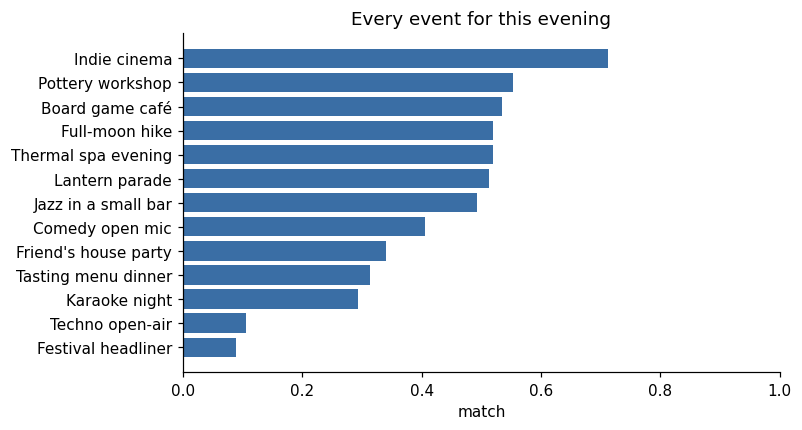

In [8]:
me = dict(
    battery='a bit tired',  # drained, tired, okay, good, buzzing
    wallet='tight',         # broke, tight, fine, treat myself
    occasion='unwind',      # unwind, catch up, celebrate, new, date
    company='partner',      # solo, partner, friends, big group, kids
)

show(me)
explain(recommend(me)[0]['name'], me)

ranked = recommend(me)[::-1]
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh([r['name'] for r in ranked], [r['score'] for r in ranked], color='#3a6ea5')
ax.set_xlim(0, 1)
ax.set_xlabel('match')
ax.set_title('Every event for this evening')
plt.show()

## Plan B

Planners always keep a backup. Here the backup comes from asking the planner again for a slightly more tired version of you.

In [9]:
def plan_b(me):
    levels = list(WORDS['battery'])
    now = me['battery'].split()[-1]
    tired_me = dict(me, battery=levels[max(levels.index(now) - 1, 0)])
    first = recommend(me)[0]['name']
    backup = next(r for r in recommend(tired_me) if r['name'] != first)
    show_md(f"Plan A: **{first}**. If you end up {tired_me['battery']} instead: **{backup['name']}** "
            f"({backup['score']:.0%}).")


plan_b(me)

Plan A: **Indie cinema**. If you end up drained instead: **Pottery workshop** (56%).

## Why fuzzy and not a filter

A normal app puts every answer in one box and filters. The plot shows how "up for it" changes as your energy goes from empty to full. The fuzzy answer changes gradually. The filter jumps between no, maybe and yes.

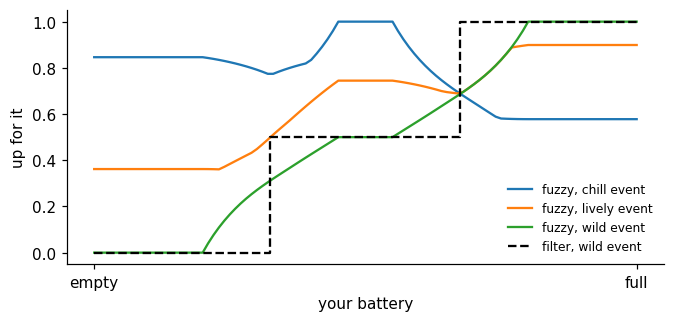

In [10]:
def point(x):
    """A crisp value as a fuzzy singleton."""
    s = np.zeros_like(X)
    s[np.argmin(np.abs(X - x))] = 1.0
    return s


def box(var, text):
    """What a filter does: put an answer in exactly one box (0 = low, 1 = mid, 2 = high)."""
    s = word(var, text)
    return int(np.argmax([possibility(s, m) for m in LEVELS.values()]))


def box_at(x):
    """Same for an exact value on the 0-10 scale."""
    return int(np.argmax([m[np.argmin(np.abs(X - x))] for m in LEVELS.values()]))


energy = np.linspace(0, 10, 101)
fig, ax = plt.subplots(figsize=(7, 3))
for it in ['chill', 'lively', 'wild']:
    ax.plot(energy, [run_check('Up for it', point(b), word('intensity', it))[0] for b in energy],
            label=f'fuzzy, {it} event')
table = CHECKS['Up for it'][1]
crisp = [{'no': 0, 'maybe': .5, 'yes': 1}[table[box_at(b)][box('intensity', 'wild')]] for b in energy]
ax.step(energy, crisp, 'k--', where='mid', label='filter, wild event')
ax.set_xticks([0, 10], ['empty', 'full'])
ax.set_xlabel('your battery')
ax.set_ylabel('up for it')
ax.legend(frameon=False, fontsize=8)
plt.show()

The same comparison on a few everyday scenarios. A filter returns an unordered set that is often empty or too large. The fuzzy planner always gives a ranking.

In [11]:
SCENARIOS = {
    'After exams':        dict(battery='drained', wallet='tight', occasion='unwind', company='partner'),
    'Birthday':           dict(battery='buzzing', wallet='treat myself', occasion='celebrate', company='friends'),
    'Saturday with kids': dict(battery='okay', wallet='fine', occasion='new', company='kids'),
    'Old friend in town': dict(battery='a bit tired', wallet='fine', occasion='catch up', company='friends'),
    'New in the city':    dict(battery='good', wallet='broke', occasion='new', company='solo'),
}


def crisp_judge(event, me):
    """How many of the four checks the event passes as a plain filter."""
    facts = {**event, **me}
    passed = sum(table[box(v1, facts[v1])][box(v2, facts[v2])] == 'yes'
                 for (v1, v2), table in CHECKS.values())
    return passed + (for_us(event, me)[0] >= 0.5)


rows = ['| Scenario | Fuzzy top 3 | Passes every filter |', '|:--|:--|:--|']
for s, who in SCENARIOS.items():
    top = ', '.join(r['name'] for r in recommend(who)[:3])
    passed = [e['name'] for e in EVENTS if crisp_judge(e, who) == 4]
    rows.append(f"| {s} | {top} | {', '.join(passed) or 'nothing'} |")
show_md('\n'.join(rows))

| Scenario | Fuzzy top 3 | Passes every filter |
|:--|:--|:--|
| After exams | Indie cinema, Pottery workshop, Board game café | Indie cinema |
| Birthday | Karaoke night, Festival headliner, Friend's house party | Jazz in a small bar, Karaoke night, Friend's house party, Tasting menu dinner, Lantern parade, Techno open-air, Festival headliner |
| Saturday with kids | Lantern parade, Pottery workshop, Indie cinema | Pottery workshop, Lantern parade |
| Old friend in town | Board game café, Full-moon hike, Friend's house party | Pottery workshop |
| New in the city | Lantern parade, Pottery workshop, Comedy open mic | nothing |

## How we could evaluate it

The feedback asked whether this makes sense to other people. Three small tests, each looking at it from a different side:

**Do people agree with the rules?** Testers read the 27 rule sentences below and mark each one agree or disagree. Rules that most people reject get changed.

**Does the ranking match what people would choose?** Testers get a scenario and the event list, without seeing our output, and rate every event from 1 to 5 ("would you go?"). We compare their ratings with the fuzzy planner and with the plain filter. We use rank correlation (Spearman) and count how many of their top 3 are also in ours. The fuzzy planner should agree with people more than the filter does.

**Do the reasons sound right?** Testers see the top suggestions with their "because" and "but" sentences, and rate from 1 to 5 how much each one sounds like something a friend would say.

About 8 to 10 testers with 3 scenarios each takes roughly 15 minutes per person. The results tell us what to adjust: a rule cell, the shape of a word, or γ.

In [12]:
sentences = [f"If {SAY[v1][i]} and {SAY[v2][j]} → {name.lower()}: **{table[i][j]}**"
             for name, ((v1, v2), table) in CHECKS.items() for i in range(3) for j in range(3)]
show_md('\n'.join(f'{k}. {s}' for k, s in enumerate(sentences, 1)))

1. If you're running low and it's a chill one → up for it: **yes**
2. If you're running low and it's lively → up for it: **maybe**
3. If you're running low and it's a wild one → up for it: **no**
4. If you're doing okay and it's a chill one → up for it: **yes**
5. If you're doing okay and it's lively → up for it: **yes**
6. If you're doing okay and it's a wild one → up for it: **maybe**
7. If you're full of energy and it's a chill one → up for it: **maybe**
8. If you're full of energy and it's lively → up for it: **yes**
9. If you're full of energy and it's a wild one → up for it: **yes**
10. If money is tight and it's cheap → affordable: **yes**
11. If money is tight and it costs a bit → affordable: **maybe**
12. If money is tight and it's pricey → affordable: **no**
13. If money is fine and it's cheap → affordable: **yes**
14. If money is fine and it costs a bit → affordable: **yes**
15. If money is fine and it's pricey → affordable: **maybe**
16. If you feel like treating yourself and it's cheap → affordable: **yes**
17. If you feel like treating yourself and it costs a bit → affordable: **yes**
18. If you feel like treating yourself and it's pricey → affordable: **yes**
19. If it happens every week and it's close → worth the trip: **yes**
20. If it happens every week and it's a short trip → worth the trip: **maybe**
21. If it happens every week and it's far → worth the trip: **no**
22. If it's a nice change and it's close → worth the trip: **yes**
23. If it's a nice change and it's a short trip → worth the trip: **yes**
24. If it's a nice change and it's far → worth the trip: **maybe**
25. If it's rare and it's close → worth the trip: **yes**
26. If it's rare and it's a short trip → worth the trip: **yes**
27. If it's rare and it's far → worth the trip: **yes**

In [13]:
def ranks(a):
    a = np.asarray(a, float)
    r = np.empty(len(a))
    r[a.argsort(kind='stable')] = np.arange(len(a))
    for v in np.unique(a):
        r[a == v] = r[a == v].mean()
    return r


def spearman(a, b):
    ra, rb = ranks(a), ranks(b)
    return float(np.corrcoef(ra, rb)[0, 1]) if ra.std() and rb.std() else float('nan')


def top3(names, scores):
    return set(np.array(names)[np.argsort(-np.asarray(scores, float), kind='stable')[:3]])


def compare(scenario, ratings):
    who = SCENARIOS[scenario]
    names = [e['name'] for e in EVENTS]
    human = [ratings[n] for n in names]
    systems = {'Fuzzy planner': [judge(e, who)[0] for e in EVENTS],
               'Plain filter': [crisp_judge(e, who) for e in EVENTS]}
    rows = [f'**{scenario}**', '', "| | Rank agreement | Tester's top 3 in our top 3 |", '|:--|--:|--:|']
    for k, s in systems.items():
        rows.append(f'| {k} | {spearman(human, s):.2f} | {len(top3(names, human) & top3(names, s))} of 3 |')
    show_md('\n'.join(rows))

The ratings below are example numbers typed in to show what the output looks like. They are not test data. In the meeting, each of us can fill in our own ratings for a scenario before looking at the planner's answer.

In [14]:
example = {  # 1 = would never go, 5 = would definitely go
    'Board game café': 3, 'Indie cinema': 5, 'Jazz in a small bar': 4, 'Thermal spa evening': 4,
    'Pottery workshop': 3, 'Comedy open mic': 3, 'Karaoke night': 1, "Friend's house party": 1,
    'Tasting menu dinner': 2, 'Full-moon hike': 2, 'Lantern parade': 2, 'Techno open-air': 1,
    'Festival headliner': 1,
}
compare('After exams', example)

**After exams**

| | Rank agreement | Tester's top 3 in our top 3 |
|:--|--:|--:|
| Fuzzy planner | 0.88 | 1 of 3 |
| Plain filter | 0.67 | 2 of 3 |